# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

### Collect data

In [2]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        statpath = os.path.join(result_dir, 'stats', dataset.path + '.csv')
        if os.path.exists(statpath):
            chunks.append(pd.read_csv(statpath))
statdata = pd.concat(chunks)
del chunks
# statdata.to_csv('./data/statdata.csv', index=False)
print('statdata successfully collected.')

100%|██████████| 1828/1828 [00:13<00:00, 133.06it/s]
statdata successfully collected.


In [3]:
# statdata = pd.read_csv('./data/statdata.csv')
print(statdata.shape)
statdata.head()

(752243, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,NaN
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,NaN
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,NaN
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN


In [4]:
print(statdata.shape)
# subset = statdata[statdata['name'] != 'Missing Values']
# subset = subset[subset['name'] != 'Continuous Endpoints (Threshold)']
# subset = subset[subset['name'] != 'Continuous Endpoints (GAMETES)']
subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset = subset[subset['description'].str.contains('h=1')]
print(subset.shape)

(752243, 11)
(746853, 11)


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

F1 scores

In [119]:
# max_f1 = subset.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
# mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
# maxmean = mean_f1.reset_index()

# rectangular = pd.pivot_table(maxmean,\
#     values='f1',\
#     index=['description'],\
#     columns=['ranking_method'])
# f, ax = plt.subplots(figsize=(7, 25))
# plt.yticks(rotation=0)
# plt.xticks(rotation=0)
# ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
# plt.title('f1 scores per unique dataset')

PR and ROC Curve

In [17]:
from tqdm import tqdm
import numpy as np

# small_subset = subset
# small_subset = subset[
#         (subset['name'] == 'Total # of Features')
#     ]

# compute means over several replicas by interpolation
def interpolate_metrics(replicas, metric_x, metric_y, roc=True):
    ys = []
    mean_x = np.linspace(0, 1, 100)
    for key, data in replicas.groupby([ 'replica_no' ]):
        x = data.sort_values(metric_x)[metric_x].values
        y = data.sort_values(metric_y)[metric_y].values
        interp_y = np.interp(mean_x, x, y)
        if roc:
            interp_y[0] = 0.0
        ys.append(interp_y)
    mean_y = np.mean(ys, axis=0)
    if roc:
        mean_y[-1] = 1.0
    auc = np.trapz(mean_y, mean_x)
    return mean_x, mean_y, auc

interpdata = []
for key, data in tqdm(subset.groupby([ 'description', 'ranking_method' ])):
    description, ranking_method = key
    fpr, tpr, roc_auc = interpolate_metrics(data, 'fpr', 'recall')
    recall, precision, pr_auc = interpolate_metrics(data, 'recall', 'precision', roc=False)
    description = description.replace(' [p=', '\n[p=')

    interpdata.append(pd.DataFrame(data={
        'description': description,
        'ranking_method': ranking_method,
        'fpr': fpr,
        'tpr': tpr,
        'recall': recall,
        'precision': precision,
        'pr_auc': pr_auc,
        'roc_auc': roc_auc
    }))
interpdata = pd.concat(interpdata)
interpdata.shape

100%|██████████| 402/402 [00:52<00:00,  7.62it/s]


(40200, 8)

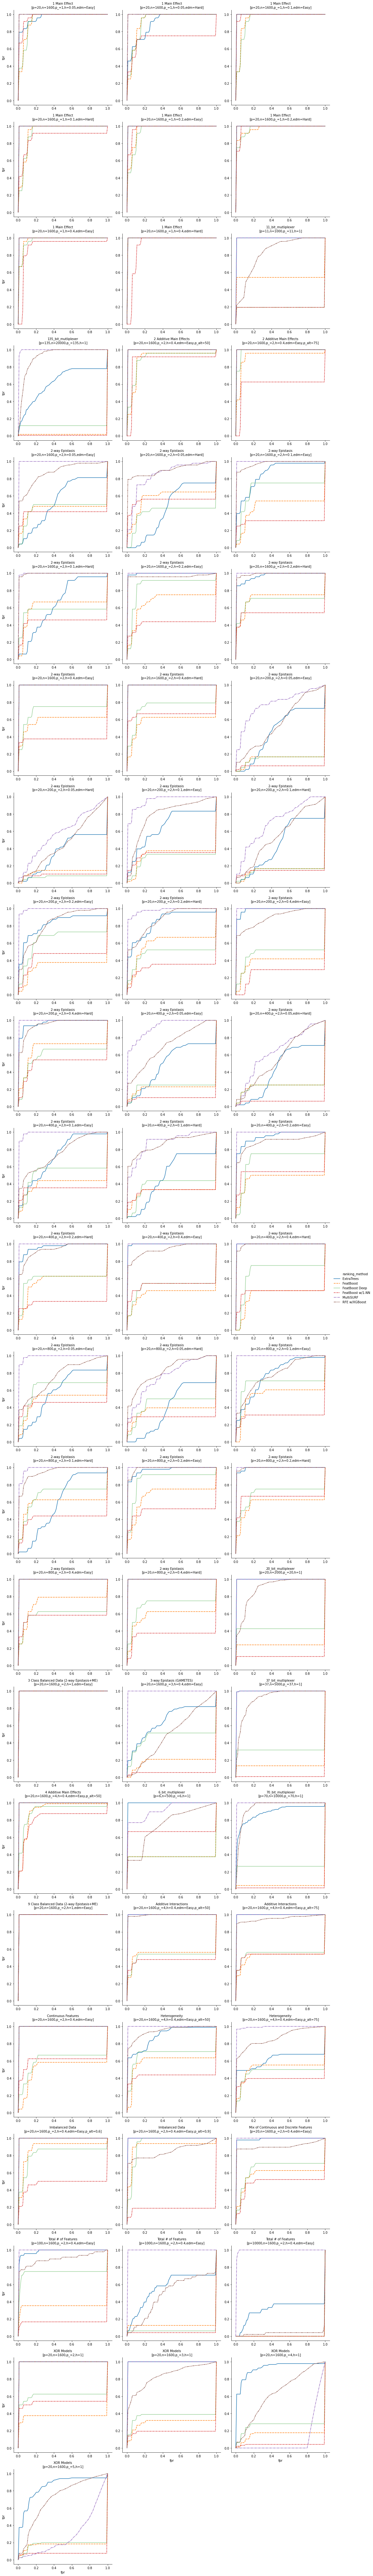

In [13]:
g = sns.relplot(data=interpdata, x='fpr', y='tpr', hue='ranking_method', style='ranking_method',
                col='description', kind='line', estimator=None,
                col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
g.set_titles("{col_name}")

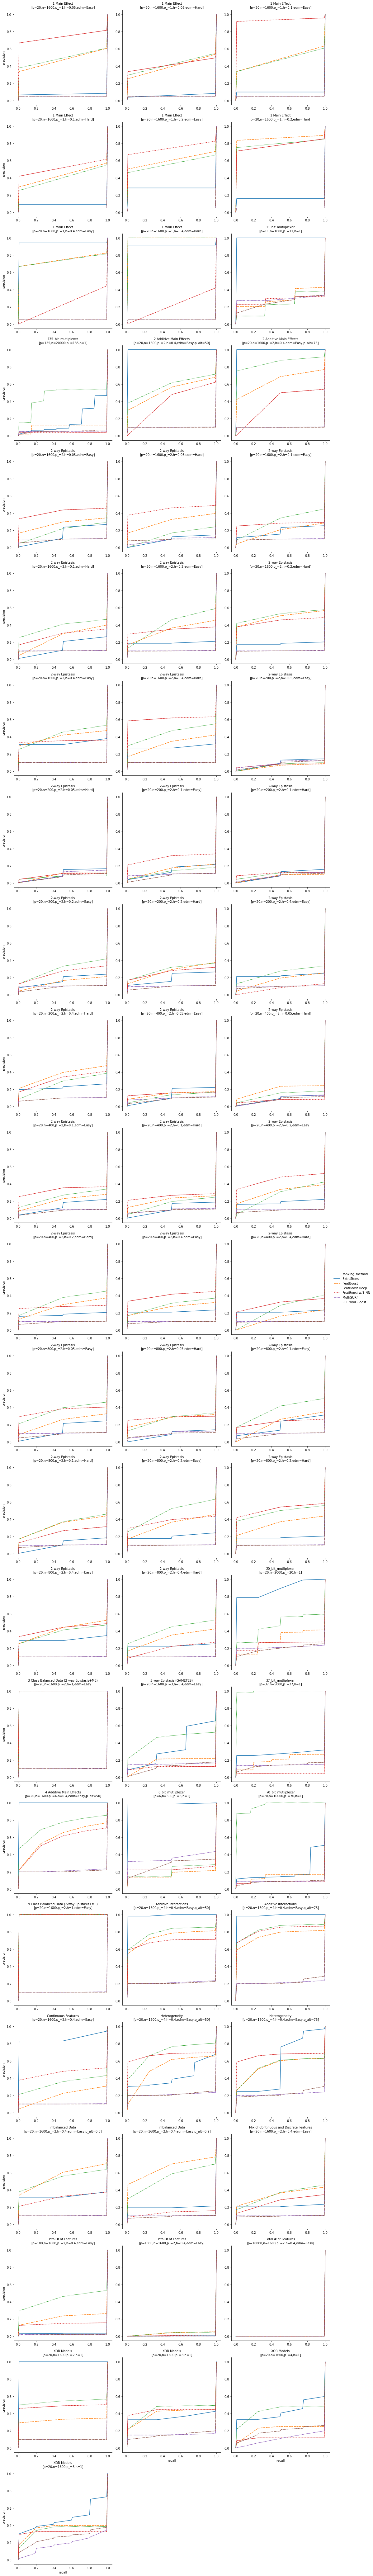

In [15]:
g = sns.relplot(data=interpdata, x='recall', y='precision', hue='ranking_method', style='ranking_method',
                col='description', kind='line', estimator=None,
                col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
g.set_titles("{col_name}")

AUC scores

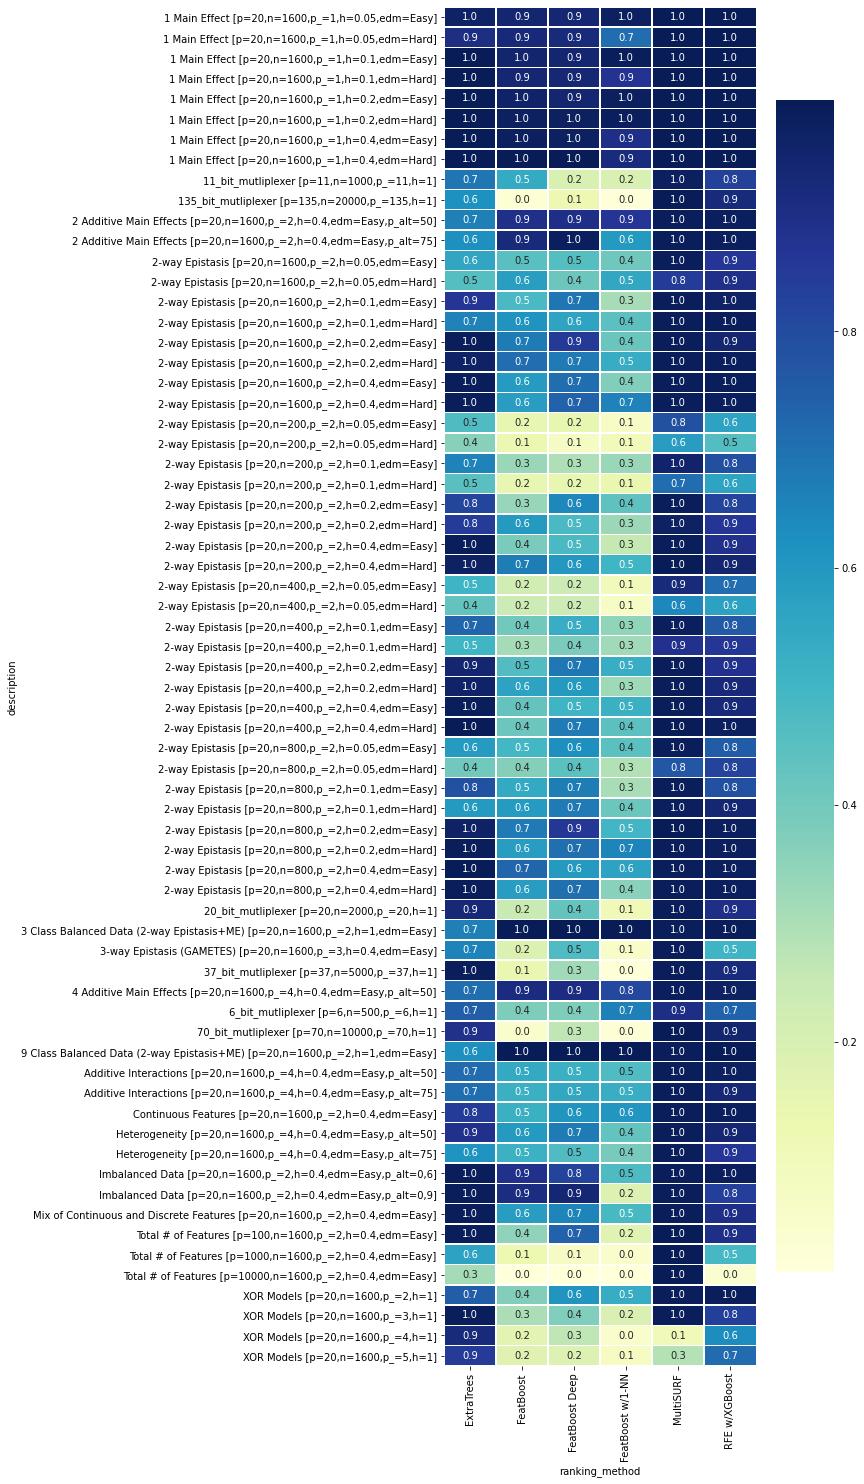

In [136]:
rocdata['description'] = rocdata['description'].str.replace('\n', ' ')
rectangular = pd.pivot_table(rocdata,\
    values='auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

In [9]:
# subset2 = subset[subset['feature_rank'] <= 20]

# from matplotlib.ticker import FuncFormatter
# rectangular = pd.pivot_table(subset2,\
#     values='recall',\
#     index=['ranking_method'],\
#     columns=['feature_rank'])
# g = sns.heatmap(rectangular,\
#     linewidths=.5, cmap="YlGnBu")
# plt.yticks(rotation=0)
# plt.xticks(rotation=0)
# plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
# plt.title('recall per ranking method for all datasets')

Construct a sensible subset for plotting

In [121]:
# subset = statdata.copy()
# for dataset, data in statdata.groupby('description'):
#     all_replicas = data.groupby('replica_no')
#     if len(all_replicas.count()) != 24: # only 'finished' datasets
#         subset = subset[subset['description'] != dataset]
#     else: # add newline in plot title
#         descr = dataset.replace(' [p=', '\n[p=')
#         descr = descr.replace(',h=', ',\nh=')
#         subset = subset.replace({ 'description': dataset }, descr)
#         # short_descr = '[p=' + dataset.split(' [p=')[1]
#         # entries = subset[subset['description'] == dataset]
#         # subset.loc[entries.index, 'short_descr'] = short_descr
# subset = subset[subset['feature_rank'] <= 20]
# subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset.shape

In [ ]:
# def draw_heatmap(*args, **kwargs):
#     data = kwargs.pop('data')
#     rect = pd.pivot_table(data, values='recall',\
#                         index=['ranking_method'],\
#                         columns=['feature_rank'])
#     sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
#     plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
#     plt.yticks(rotation=0)
#     plt.xticks(rotation=0)

# def pltrecall(data, title):
#     fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
#     fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
#     fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
#     # plt.subplots_adjust(top=0.875)
#     # fg.fig.suptitle(title)
#     # fg.fig.tight_layout()

# for name, data in subset2.groupby('name'):
#     pltrecall(data, name)

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

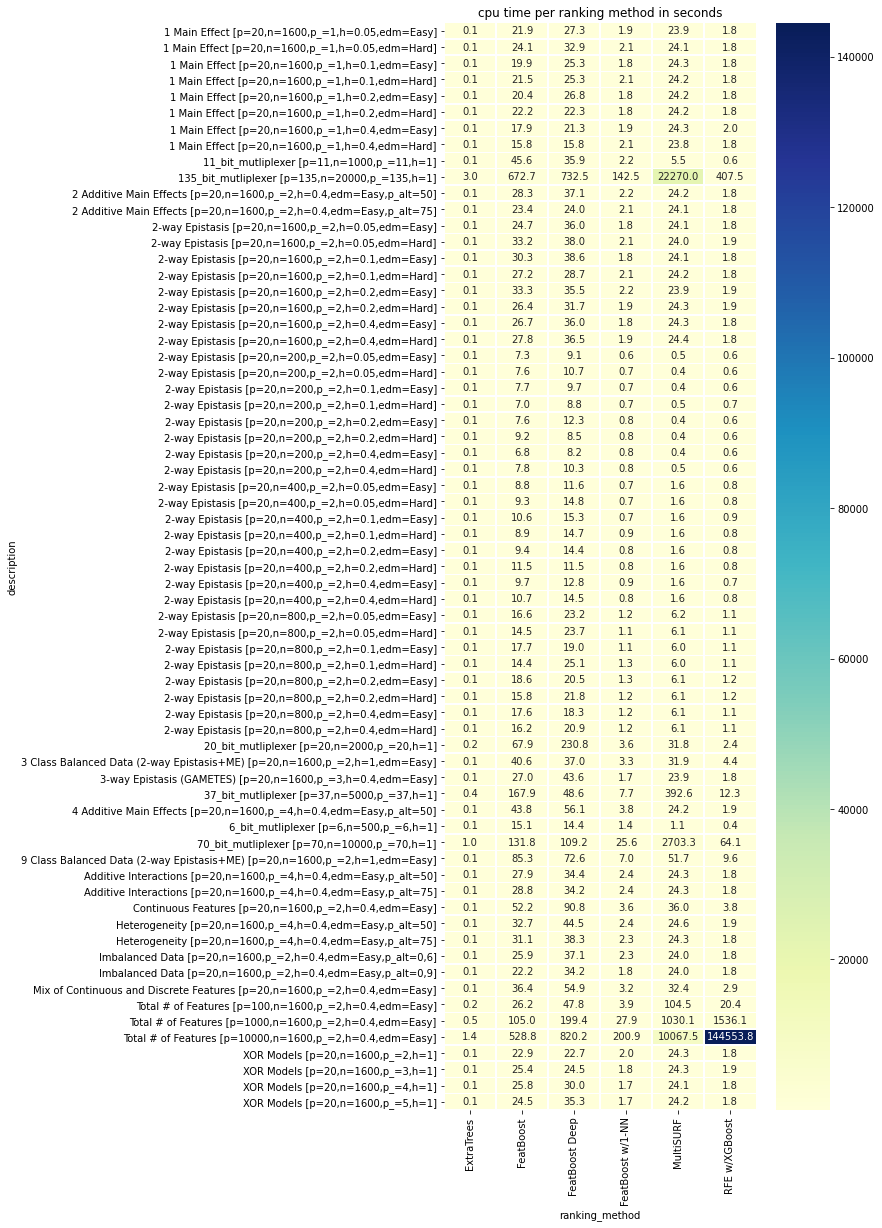

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(subset,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')